# Module End  Assignment: Python For Data Analysis

Project Title: Social Media Engagement Analytics Using Python
Problem Statement

Task 1 — Data Import & Setup

In [3]:
from google.colab import files
uploaded=files.upload()

Saving social_media_engagement_5000.csv to social_media_engagement_5000.csv


In [4]:
import pandas as pd

In [5]:
df=pd.read_csv('social_media_engagement_5000.csv')
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,25-06-2022,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,18-11-2022,584603,False,desktop,negative,#foodie #reels,0.621155
4997,67021,63.0,Female,USA,273595,text,travel,13487.0,NaN,167.0,7466,23680,06-04-2023,483550,False,desktop,positive,#lifestyle #tech,0.679688
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,16-05-2022,183295,False,tablet,positive,#reels #love #fitness,0.223518


In [ ]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [6]:
df.dtypes

,0
user_id,int64
age,float64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,float64
shares,float64


In [7]:
df['age']=df['age'].astype('Int64')
df['likes']=df['likes'].astype('Int64')
df['shares']=df['shares'].astype('Int64')
df['comments']=df['comments'].astype('Int64')
df.dtypes

,0
user_id,int64
age,Int64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,Int64
comments,Int64
shares,Int64


In [9]:
df['posted_at']=pd.to_datetime(df['posted_at'],errors='coerce')
print(df['posted_at'].dtype)

datetime64[ns]


**Task 2 — Data Cleaning**

Cleaning Missing Data-The first step of data cleaning was to identify missing values in each column. This helps us understand the quality of the dataset and decide how to handle incomplete data before proceeding with further analysis.

* Here using isnull() identifies the missing values in the dataset and sum() counts the missing values

* Columns like age, gender, likes,comments, shares,sentiments have contains missing values.


In [10]:
df.isnull().sum() # find missing values column

,0
user_id,0
age,150
gender,150
country,0
post_id,0
post_type,0
post_category,0
likes,150
comments,150
shares,150


Handling missing values

Age column

* Firstly calculated skewness of the Age column to understand the distribution of the data. The skewness value was 0.0206, which indicates that the data is approximately symmetrical

* Since the age column has the datatype int, here use median instead of mean,   median provides a whole number value and maintains the integer format of the column

In [11]:
df['age'].skew()

np.float64(0.02061542014790882)

In [12]:
print('mean:',df['age'].mean())
print('median:',df['age'].median())

mean: 38.454020618556704
median: 38.0


In [13]:
df['age']=df['age'].fillna(df['age'].median())
df['age'].isnull().sum()

np.int64(0)

Gender column
* Replaced missing values in the gender column with 'Unknown'.

In [14]:
df['gender']=df['gender'].fillna('Unknown')
df['gender'].isnull().sum()

np.int64(0)

In [15]:
df['gender'].value_counts()

,count
gender,
Male,1699
Other,1581
Female,1570
Unknown,150


Likes column
* The missing values in the likes column is filled with the medain value

In [16]:
df['likes'].skew()

np.float64(-0.00681349410417789)

In [17]:
print('mean:',df['likes'].mean())
print('median:' , df['likes'].median())

mean: 10107.043711340206
median: 10105.5


In [18]:
df['likes']=df['likes'].astype(float)
df['likes'].dtype

dtype('float64')

In [19]:
df['likes']=df['likes'].fillna(df['likes'].median())
df['likes'].isnull().sum()

np.int64(0)

Comments column
 * Here also the skew value is approximately zero so we can use either mean or median , here i use median beacuse median provides a wholenumber value and maintains the integer format of the column

In [20]:
df['comments'].skew()

np.float64(0.003206324966861445)

In [21]:
print('mean:',df['comments'].mean())
print('median:', df['comments'].median())

mean: 1502.1956701030929
median: 1497.0


In [22]:
df['comments']=df['comments'].fillna(df['comments'].median())
df['comments'].isnull().sum()

np.int64(0)

Shares column
* Handled the missing values with median

In [23]:
df['shares'].skew()

np.float64(-0.0129769182180636)

In [24]:
print('mean:', df['shares'].mean())
print('median:', df['shares'].median())

mean: 1002.6294845360825
median: 1012.0


In [25]:
df['shares']=df['shares'].fillna(df['shares'].median())
df['shares'].isnull().sum()

np.int64(0)

Sentiment column
* The missing values in the sentiment column is repalced with 'unknown' .

In [26]:
df['sentiment']=df['sentiment'].fillna('unknown')
df['sentiment'].isnull().sum()

np.int64(0)

 * Duplicate Handling-checks the duplicate value using duplicated() function , but the ouput is zero so the dataframe consists of no duplicates.


In [27]:
df.duplicated().sum()

np.int64(0)

* Data Formatting

In [28]:
df.dtypes # fix incorrect data types

,0
user_id,int64
age,Int64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,Int64
shares,Int64


* Standardize categories (e.g., gender labels)

In [29]:
df['gender']=df['gender']=df['gender'].str.title()  #gender column
df['gender'].unique()

array(['Female', 'Male', 'Other', 'Unknown'], dtype=object)

In [30]:
df['sentiment']=df['sentiment'].str.title()          #sentiment column
df['sentiment'].unique()

array(['Negative', 'Positive', 'Neutral', 'Unknown'], dtype=object)

In [31]:
df['country'].str.title() #country column
df['country'].unique()

array(['Brazil', 'UK', 'France', 'Canada', 'Japan', 'Australia', 'India',
       'UAE', 'Germany', 'USA'], dtype=object)

In [32]:
df['post_type'].unique()  #post type column

array(['image', 'reel', 'text', 'video'], dtype=object)

In [33]:
df['post_type']=df['post_type'].str.title()
df['post_type'].unique()

array(['Image', 'Reel', 'Text', 'Video'], dtype=object)

In [34]:
df['post_category'].unique() #post category coulumn

array(['fitness', 'food', 'tech', 'travel', 'fashion', 'lifestyle',
       'education', 'music'], dtype=object)

In [53]:
df['post_category']=df['post_category'].str.title()
df['post_category'].unique()

array(['Fitness', 'Food', 'Tech', 'Travel', 'Fashion', 'Lifestyle',
       'Education', 'Music'], dtype=object)

In [ ]:
df['device_type'].unique()    #device type column

array(['mobile', 'tablet', 'desktop'], dtype=object)

In [35]:
df['device_type']=df['device_type'].str.title()
df['device_type'].unique()

array(['Mobile', 'Tablet', 'Desktop'], dtype=object)

* Correct unrealistic values in likes, comments, shares
     * Here we find minimum and maximum values to identify the presence of any unrealistic values like negative,  high range or low range values. No unexpceted values present in the df.

In [ ]:
print(df[['likes', 'comments', 'shares']].min())

likes       10.0
comments     0.0
shares       0.0
dtype: Float64


In [ ]:
print(df[['likes','comments','shares']].max())

likes       19998.0
comments     2999.0
shares       1999.0
dtype: Float64


* Feature Cleaning
   * Extract hashtag count

In [ ]:
df['hashtags'].count()  # hash tag count

np.int64(5000)

* Clean sentiment labels

In [ ]:
df['sentiment']=df['sentiment'].str.strip()
df['sentiment'].unique()

array(['Negative', 'Positive', 'Neutral', 'Unknown'], dtype=object)

**Task 3 — Data Exploration using Pandas**

* Viewing the  dataset structure using head(), tail(), shape, and columns

In [ ]:
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43,Female,Brazil,496713,Image,Fitness,7011.0,354,1157,5726,44650,2022-12-17,81734,False,Mobile,Negative,#foodie #travel #love,0.190862
1,10860,33,Male,Brazil,157326,Reel,Food,11750.0,2606,1807,5947,80216,2023-06-02,5963,False,Mobile,Negative,#fitness,0.201493
2,86820,32,Female,UK,109864,Text,Food,4862.0,344,955,6946,44858,2023-05-07,501783,False,Tablet,Positive,#foodie,0.137345
3,64886,51,Other,France,848877,Text,Fitness,5350.0,1083,1049,229,70455,2023-02-12,480212,False,Mobile,Negative,#music #foodie #fun,0.106195
4,16265,34,Other,UK,449706,Image,Fitness,12682.0,2735,1300,4798,6019,2023-05-23,383936,False,Mobile,Negative,#travel,2.777372


In [ ]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
4995,59500,44,Male,Australia,441541,Video,Education,16210.0,2013,1837,6190,42977,2022-06-25,646147,False,Mobile,Positive,#travel #fun,0.466761
4996,22100,38,Other,UAE,677076,Reel,Education,16924.0,2734,1583,7764,34196,2022-11-18,584603,False,Desktop,Negative,#foodie #reels,0.621155
4997,67021,63,Female,USA,273595,Text,Travel,13487.0,1497,167,7466,23680,2023-04-06,483550,False,Desktop,Positive,#lifestyle #tech,0.679688
4998,29800,13,Female,Germany,785644,Video,Fitness,16894.0,1289,1713,4991,89013,2022-05-16,183295,False,Tablet,Positive,#reels #love #fitness,0.223518
4999,73400,54,Other,Japan,712252,Text,Travel,14830.0,503,1798,3743,14234,2023-03-04,585760,False,Desktop,Neutral,#foodie #lifestyle #fashion,1.203527


In [ ]:
df.shape

(5000, 19)

In [ ]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='object')

 * Check data types and info with info() and dtypes

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   Int64         
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   float64       
 8   comments          5000 non-null   Int64         
 9   shares            5000 non-null   Int64         
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

In [ ]:
df.dtypes # check datatypes

,0
user_id,int64
age,Int64
gender,object
country,object
post_id,int64
post_type,object
post_category,object
likes,float64
comments,Int64
shares,Int64


* Generate summary statistics using describe().

In [ ]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate
count,5000.000000,5000.0,5000.000000,5000.000000,5000.0,5000.0,5000.000000,5000.000000,5000,5000.000000,5000.000000
mean,54561.890800,38.4404,548042.909000,10106.997400,1502.0398,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356
min,10055.000000,13.0,100068.000000,10.000000,0.0,0.0,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363
25%,32309.500000,26.0,322543.500000,5235.000000,792.0,511.0,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781
50%,54374.500000,38.0,548077.500000,10105.500000,1497.0,1012.0,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896
75%,77180.500000,51.0,771574.500000,14959.000000,2235.25,1483.0,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794
max,99963.000000,64.0,999455.000000,19998.000000,2999.0,1999.0,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348
std,26090.370121,14.687151,260646.957267,5702.293017,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029


* Analyze categorical distributions using value_counts(), unique(), and nunique().

In [ ]:
df['gender'].unique()  # gender


array(['Female', 'Male', 'Other', 'Unknown'], dtype=object)

In [ ]:
df['gender'].nunique()

4

In [ ]:
df['gender'].value_counts()

,count
gender,
Male,1699
Other,1581
Female,1570
Unknown,150


In [ ]:
df['country'].unique()  #country

array(['Brazil', 'UK', 'France', 'Canada', 'Japan', 'Australia', 'India',
       'UAE', 'Germany', 'USA'], dtype=object)

In [ ]:
df['country'].nunique()

10

In [ ]:
df['country'].value_counts()

,count
country,
India,535
Canada,513
Brazil,504
UAE,503
USA,501
France,496
UK,493
Australia,493
Germany,490


In [ ]:
df['post_type'].unique()  #post type

array(['Image', 'Reel', 'Text', 'Video'], dtype=object)

In [ ]:
df['post_type'].nunique()

4

In [ ]:
df['post_type'].value_counts()

,count
post_type,
Reel,1283
Image,1247
Text,1245
Video,1225


In [ ]:
df['post_category'].unique()  #post category

array(['Fitness', 'Food', 'Tech', 'Travel', 'Fashion', 'Lifestyle',
       'Education', 'Music'], dtype=object)

In [ ]:
df['post_category'].nunique()

8

In [ ]:
df['post_category'].value_counts()

,count
post_category,
Fitness,675
Tech,665
Music,635
Education,631
Lifestyle,607
Travel,600
Fashion,594
Food,593


In [ ]:
df['device_type'].unique()  #device type

array(['Mobile', 'Tablet', 'Desktop'], dtype=object)

In [ ]:
df['device_type'].nunique()

3

In [ ]:
df['device_type'].value_counts()

,count
device_type,
Mobile,1684
Tablet,1658
Desktop,1658


In [ ]:
df['sentiment'].unique()   # sentiment

array(['Negative', 'Positive', 'Neutral', 'Unknown'], dtype=object)

In [ ]:
df['sentiment'].nunique()

4

In [ ]:
df['sentiment'].value_counts()

,count
sentiment,
Positive,2363
Neutral,1527
Negative,960
Unknown,150


* Create a correlation matrix for numeric fields.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

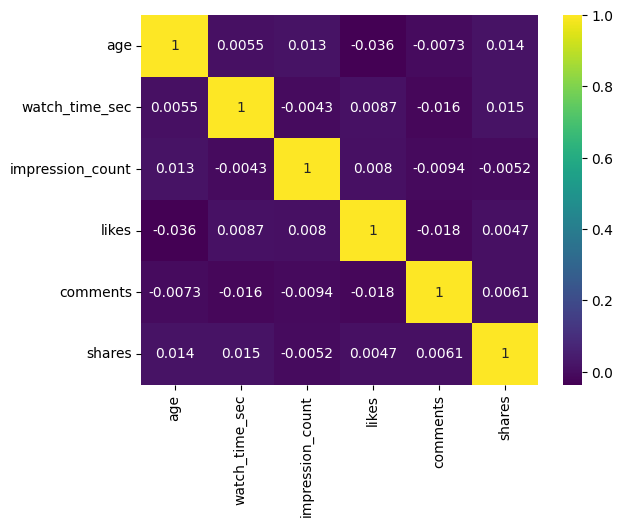

In [ ]:
correlation= df[['age','watch_time_sec','impression_count','likes','comments','shares',]].select_dtypes(include='number').corr()
sns.heatmap(correlation,annot=True,cmap='viridis')

plt.show()


* Use groupby() to summarize metrics (e.g., avg likes by post type, impressions by country).

In [ ]:
df.groupby('post_type')['likes'].mean()

,likes
post_type,
Image,10104.865277
Reel,10037.802416
Text,10100.148193
Video,10188.600000


In [ ]:
df.groupby('country')['impression_count'].mean()

,impression_count
country,
Australia,48346.383367
Brazil,49193.174603
Canada,48703.150097
France,51727.673387
Germany,48605.406122
India,52462.386916
Japan,49616.135593
UAE,48928.413519
UK,51119.393509


**Task 4 — Data Wrangling **

* Use merge, concat, or join if combining DataFrames.

In [56]:
df1 = df[['user_id', 'gender', 'post_category','post_type']]
df2 = df[['user_id','likes', 'comments', 'shares']]


In [57]:
df1.head()

,user_id,gender,post_category,post_type
0,25795,Female,Fitness,Image
1,10860,Male,Food,Reel
2,86820,Female,Food,Text
3,64886,Other,Fitness,Text
4,16265,Other,Fitness,Image


In [58]:
df2.head()

,user_id,likes,comments,shares
0,25795,7011.0,354,1157
1,10860,11750.0,2606,1807
2,86820,4862.0,344,955
3,64886,5350.0,1083,1049
4,16265,12682.0,2735,1300


In [59]:
df_merged=pd.merge(df1,df2,on='user_id')
df_merged.head()

,user_id,gender,post_category,post_type,likes,comments,shares
0,25795,Female,Fitness,Image,7011.0,354,1157
1,10860,Male,Food,Reel,11750.0,2606,1807
2,86820,Female,Food,Text,4862.0,344,955
3,64886,Other,Fitness,Text,5350.0,1083,1049
4,16265,Other,Fitness,Image,12682.0,2735,1300


**Task 5 — Statistical Analysis**


In [ ]:
df['likes'].describe()  #likes column

,likes
count,5000.000000
mean,10106.997400
std,5702.293017
min,10.000000
25%,5235.000000
50%,10105.500000
75%,14959.000000
max,19998.000000


In [ ]:
df['likes'].skew()

np.float64(-0.006893616532184278)

In [ ]:
df['comments'].describe()    #comments column

,comments
count,5000.0
mean,1502.0398
std,856.393312
min,0.0
25%,792.0
50%,1497.0
75%,2235.25
max,2999.0


In [ ]:
df['comments'].skew()

np.float64(0.0038017289479831415)

In [ ]:
df['shares'].describe()   #shares column

,shares
count,5000.0
mean,1002.9106
std,570.8552
min,0.0
25%,511.0
50%,1012.0
75%,1483.0
max,1999.0


In [ ]:
df['shares'].skew()

np.float64(-0.014653583910311461)

In [ ]:
df['watch_time_sec'].describe()   # watch time sec coloumn

,watch_time_sec
count,5000.000000
mean,4014.503200
std,2308.096459
min,0.000000
25%,2017.750000
50%,4034.500000
75%,6020.250000
max,7998.000000


In [ ]:
df['watch_time_sec'].skew()

np.float64(-0.018196273193231846)

In [ ]:
df['follower_count'].describe()   # follower count column

,follower_count
count,5000.000000
mean,393698.224800
std,230927.884535
min,87.000000
25%,194480.000000
50%,388982.000000
75%,589744.250000
max,799533.000000


In [ ]:
df['follower_count'].skew()

np.float64(0.04111777394961326)

In [ ]:
df['engagement_rate'].describe()  #engagement rate

,engagement_rate
count,5000.000000
mean,0.964356
std,5.318029
min,0.006363
25%,0.145781
50%,0.253896
75%,0.504794
max,191.504348


In [ ]:
df['engagement_rate'].skew()

np.float64(18.781270878869154)

**Task 6 — Data Visualization**

In [ ]:
import matplotlib.pyplot as plt

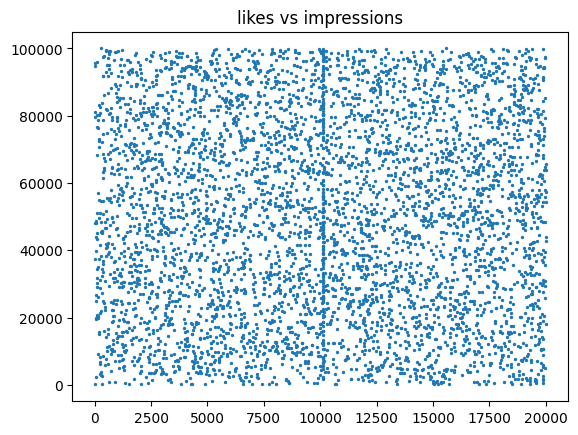

np.float64(0.007952189924959845)

In [ ]:
# Scatter: likes vs impressions
plt.scatter(df['likes'],df['impression_count'],s=2)
plt.title('likes vs impressions')
plt.show()
df['likes'].corr(df['impression_count'])

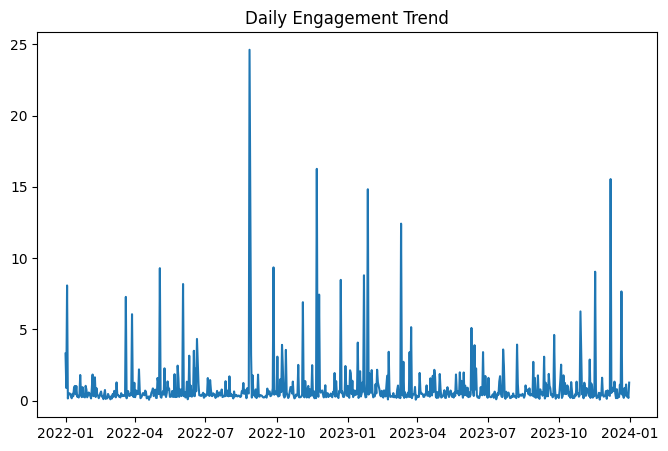

In [ ]:
# Line: daily engagement trend
daily = df.groupby('posted_at')['engagement_rate'].mean()
plt.figure(figsize=(8,5))
plt.plot(daily)
plt.title('Daily Engagement Trend')


plt.show()

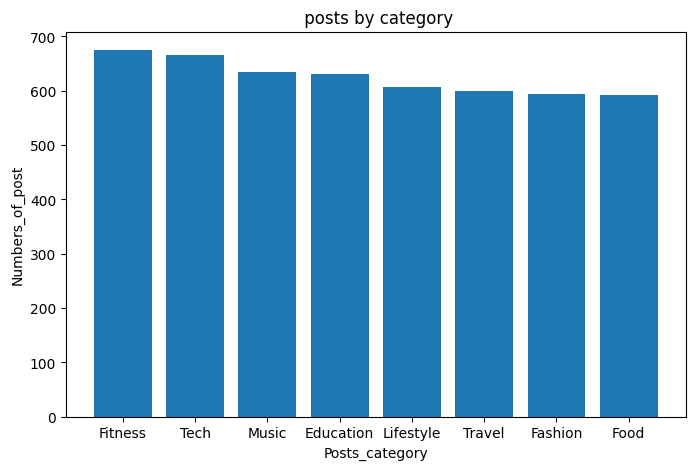

In [ ]:
# Bar: posts by category
plt.figure(figsize=(8,5))
plt.bar(df['post_category'].value_counts().index,
        df['post_category'].value_counts().values)
plt.title(' posts by category')
plt.xlabel('Posts_category')
plt.ylabel('Numbers_of_post')
plt.show()

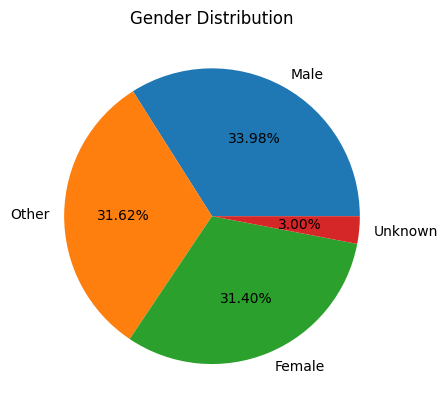

In [ ]:
#Pie: gender distribution
gender_count = df['gender'].value_counts()

plt.pie(gender_count,labels=gender_count.index, autopct='%1.2f%%')
plt.title('Gender Distribution')
plt.show()

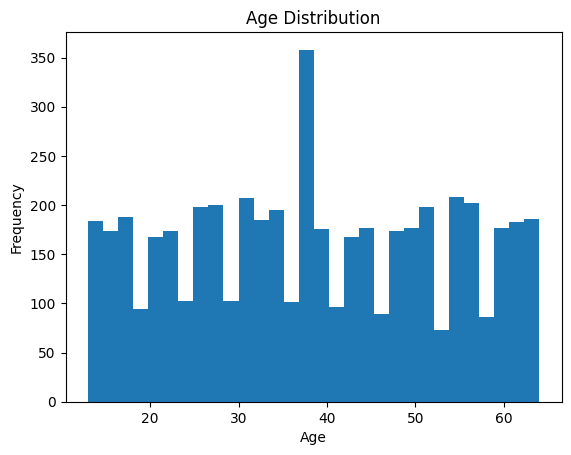

In [ ]:
# histogram age
plt.hist(df['age'],bins=30)
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title("Age Distribution")
plt.show()

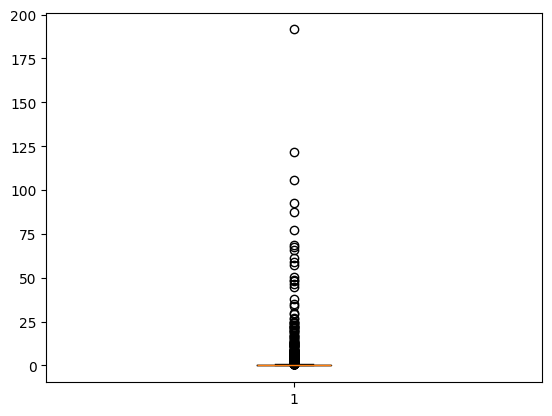

In [ ]:
# Box: engagement rate

plt.boxplot(df['engagement_rate'])
plt.show()

Seaborn

In [ ]:
import seaborn as sns

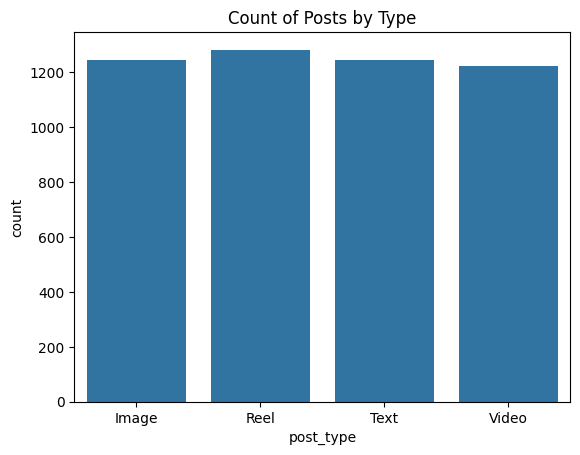

In [ ]:
# Count plot: post type

sns.countplot(x='post_type',data=df)
plt.title('Count of Posts by Type')
plt.show()

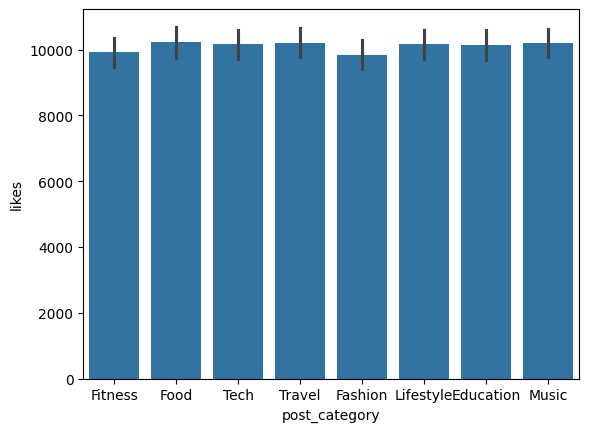

In [ ]:
# Bar plot: avg likes by category

sns.barplot(x='post_category',y='likes',data=df)
plt.show()

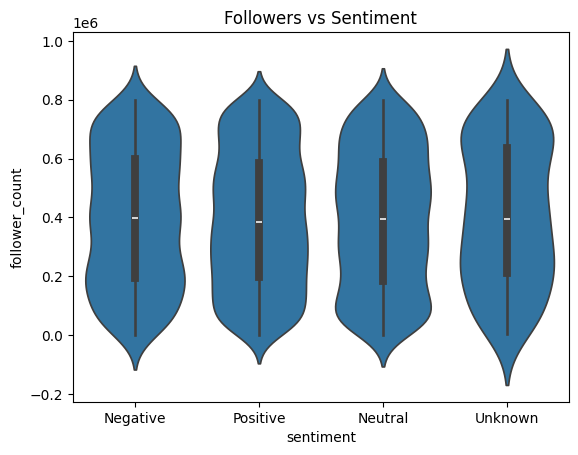

In [ ]:
# Violin: followers vs sentiment
sns.violinplot(data=df,x='sentiment',y='follower_count')
plt.title('Followers vs Sentiment')
plt.show()


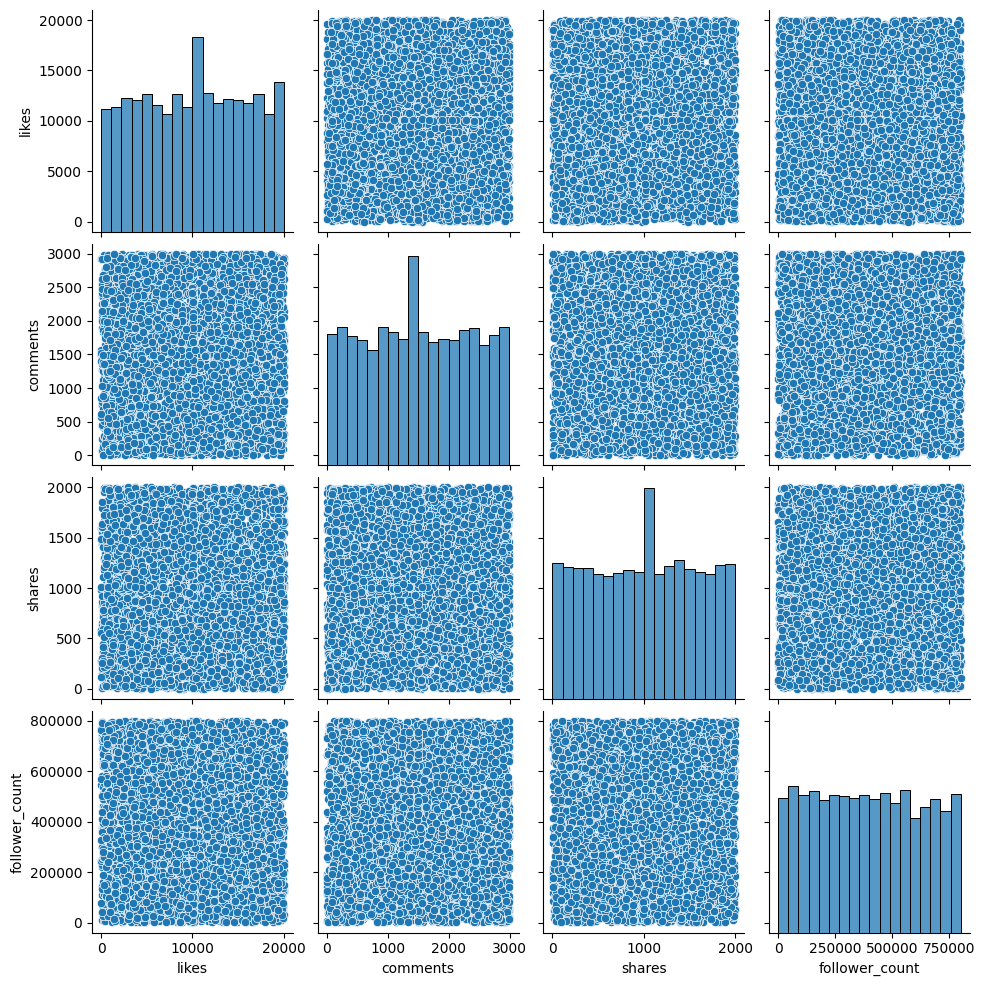

In [ ]:
# Pair plot: numeric features

sns.pairplot(df[['likes', 'comments', 'shares', 'follower_count']])
plt.show()

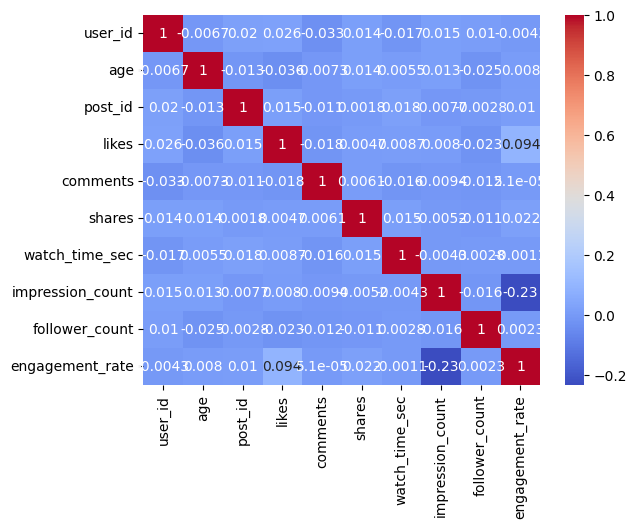

In [ ]:
# Heatmap: correlation matrix
correlation=df.select_dtypes(include='number').corr()
sns.heatmap(correlation,annot=True,cmap='coolwarm')
plt.show()

* Plotly (Interactive)

In [52]:
import plotly.express as px
import matplotlib.pyplot as plt

fig = px.bar(df, x='post_type', y='likes',color='post_type',title='Likes by Post Type')
fig.show()

# Final Insights

* Content Performance

* Post types have highest engagement-From the below code we can understand that viedo post type has the highest engagement rate , that viedo is commonly used amoong users rather than other post types.

In [36]:
# post type that have highest engagemnt rate
df.groupby('post_type')['engagement_rate'].mean().sort_values(ascending=False)

,engagement_rate
post_type,
Video,1.122365
Text,1.064549
Image,0.895646
Reel,0.783047


* Best performing content category-From the below code we can identify that food type video is commonly viewing among users, because it has the highest engagement rate .

In [54]:
# Best-performing content category
df.groupby('post_category')['engagement_rate'].mean().sort_values(ascending=False)

,engagement_rate
post_category,
Food,1.358628
Tech,1.160475
Lifestyle,1.091019
Music,0.888803
Fitness,0.865628
Education,0.844222
Fashion,0.807109
Travel,0.702223


* Countries have highest avg engagement rate-From the below code we can see that Brazil has the highest average engagement rate compared to the other countries in the dataset.

In [39]:
#  countries have highest avg engagement rate
df.groupby('country')['engagement_rate'].mean().sort_values(ascending=False)

,engagement_rate
country,
Brazil,1.540704
Australia,1.324339
France,1.146402
UAE,1.112352
Canada,0.916659
UK,0.850966
Japan,0.769623
Germany,0.759000
India,0.655005


* User Trends

* Age affects engagement-From the below scatter plot we can identify that weak relationship between age and engagement rate. Most users are from the different age groups.

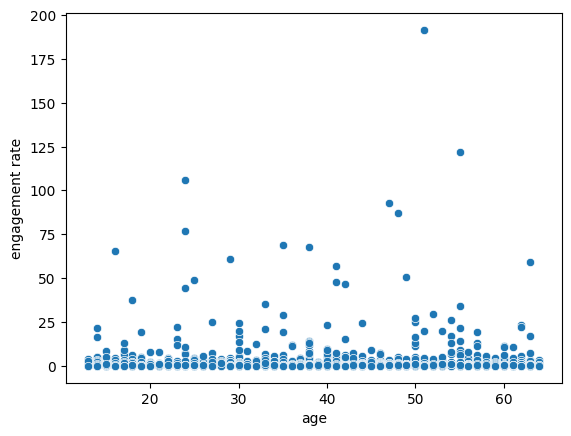

In [46]:
# age affects engagement rate
import matplotlib.pyplot as plt
import seaborn as sns
sns.scatterplot(x='age', y='engagement_rate', data=df)
plt.xlabel('age')
plt.ylabel('engagement rate')
plt.show()


* Performance difference for verified accounts- From the below group by code it can identify that non verified accounts have high engagement rate.

In [49]:
df['is_verified'].value_counts()

,count
is_verified,
False,4517
True,483


In [51]:
df.groupby('is_verified')['engagement_rate'].mean()

,engagement_rate
is_verified,
False,0.954744
True,1.054250
